# 01 · Data understanding

**Questions this notebook answers**

1. What is in the dataset, and where does it come from?
2. Is it structurally clean (schema, missing values, duplicates, value ranges)?
3. Are there signs about how the data was generated that limit what we can claim?
4. How rare is fraud, and how is the data split for honest evaluation?
5. What business problem are we solving, and how do we price a mistake?

All logic lives in `src/fraud_e2e/`; this notebook calls it and explains the results.
Every number in the text below is computed in this notebook, not typed by hand.

In [1]:
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import chi2_contingency

from fraud_e2e import config as C
from fraud_e2e import plots as P
from fraud_e2e import stats as S
from fraud_e2e.cost import load_cost_params
from fraud_e2e.data import load_raw, plausibility_checks, quality_checks
from fraud_e2e.reporting import write_json
from fraud_e2e.splits import attach_splits

P.set_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

## 1. Source and provenance

- **Dataset:** *Credit Card Fraud Detection 2026* by Udit Jain, Kaggle, licence **CC0 (public domain)**.
  <https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026>
- **Provenance:** the data card does not say whether the rows are real bank transactions or synthetic.
  This project treats it as a **public CC0 dataset of unspecified provenance** and makes no claim
  that results transfer to real card traffic.
- The loader checks the file's SHA-256 so every result is tied to one exact file.

In [2]:
df = load_raw()
print(f"Loaded {C.RAW_CSV.name}: {df.shape[0]:,} rows x {df.shape[1]} columns (sha256 verified)")
df.head()

Loaded credit_card_fraud_2026.csv: 20,000 rows x 26 columns (sha256 verified)


,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,22.35,39,25,1080.71,False,False,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,35.28,47,33,4463.72,True,False,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,9.82,51,59,366.25,False,True,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,19.72,48,28,1345.29,True,False,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,17.68,43,36,4192.59,False,False,False,False,0,3.9,2,4,False,32.7,0,0


## 2. Columns

One row is one card transaction. `transaction_id` is a row identifier (never used as a feature)
and `is_fraud` is the target. The 24 features fall into four groups.

In [3]:
group = {
    **{c: "categorical" for c in C.CATEGORICAL_COLS},
    **{c: "boolean" for c in C.BOOLEAN_COLS},
    **{c: "discrete (count/clock)" for c in C.DISCRETE_COLS},
    **{c: "continuous" for c in C.CONTINUOUS_COLS},
    C.ID_COL: "identifier",
    C.TARGET: "target",
}
schema = pd.DataFrame(
    {
        "column": df.columns,
        "group": [group[c] for c in df.columns],
        "dtype": [str(t) for t in df.dtypes],
        "n_unique": [df[c].nunique() for c in df.columns],
        "example": [df[c].iloc[0] for c in df.columns],
    }
)
schema

,column,group,dtype,n_unique,example
0,transaction_id,identifier,int64,20000,1
1,amount_usd,continuous,float64,12782,42.86
2,merchant_category,categorical,category,12,Restaurants
3,card_type,categorical,category,5,Visa
4,auth_method,categorical,category,5,OTP
5,channel,categorical,category,5,Online
6,device_type,categorical,category,8,Android Phone
7,is_foreign_transaction,boolean,bool,2,False
8,hours_since_last_txn,continuous,float64,3296,13.54
9,txn_count_last_24h,discrete (count/clock),int64,13,2


In [4]:
df[C.CONTINUOUS_COLS + C.DISCRETE_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
amount_usd,20000.0,132.42,256.96,1.00,26.24,57.51,131.75,6872.69
hours_since_last_txn,20000.0,8.95,8.84,0.01,2.59,6.21,12.43,87.05
distance_from_home_km,20000.0,22.14,22.12,0.00,6.34,15.50,30.82,216.19
card_age_months,20000.0,46.94,6.77,22.00,42.00,47.00,51.00,74.00
customer_age,20000.0,49.67,18.49,18.00,34.00,50.00,66.00,81.00
account_balance_usd,20000.0,3316.66,4350.72,52.05,1019.14,2007.68,3944.12,127125.86
velocity_score,20000.0,19.81,12.37,0.00,10.70,18.80,27.60,74.40
merchant_risk_score,20000.0,37.40,17.06,0.00,25.60,35.70,47.30,100.00
txn_count_last_24h,20000.0,3.19,1.78,0.00,2.00,3.00,4.00,12.00
cvv_retry_count,20000.0,0.18,0.42,0.00,0.00,0.00,0.00,3.00


## 3. Structural quality checks

Schema, missing values, duplicates, allowed category levels and plausible numeric ranges.
The ranges were written down as common-sense bounds (e.g. hour 0–23, age ≥ 18), not fitted to the data.
These checks do not look at the label's relationship with features, so they use all rows.

In [5]:
qc = quality_checks(df)
qc_table = pd.DataFrame([{"check": q["check"], "passed": q["passed"]} for q in qc])
n_failed = int((~qc_table["passed"]).sum())
print(f"{len(qc_table)} checks, {n_failed} failed")
qc_table[~qc_table["passed"]] if n_failed else qc_table.head(12)

26 checks, 0 failed


,check,passed
0,columns_match_schema,True
1,row_count,True
2,no_missing_values,True
3,id_unique,True
4,id_contiguous_1_to_n,True
5,no_duplicate_rows_excluding_id,True
6,no_duplicate_feature_vectors,True
7,target_is_binary,True
8,levels_merchant_category,True
9,levels_card_type,True


## 4. Plausibility of cross-column combinations

Some combinations would be unusual for real card traffic, for example a cash-machine
transaction made from a smart watch, or an in-store (POS/contactless) payment made from a desktop PC.
We count them; we do **not** remove them, because the dataset is used as published.

In [6]:
plaus = pd.DataFrame(plausibility_checks(df))
plaus["share_%"] = (plaus["share_of_rows"] * 100).round(2)
plaus[["rule", "n_rows", "share_%"]]

,rule,n_rows,share_%
0,atm_channel_on_non_atm_device,1295,6.48
1,atm_device_on_non_atm_channel,926,4.63
2,card_present_channel_on_desktop,1685,8.43
3,shipping_mismatch_at_atm,25,0.12
4,amount_exceeds_account_balance,305,1.52


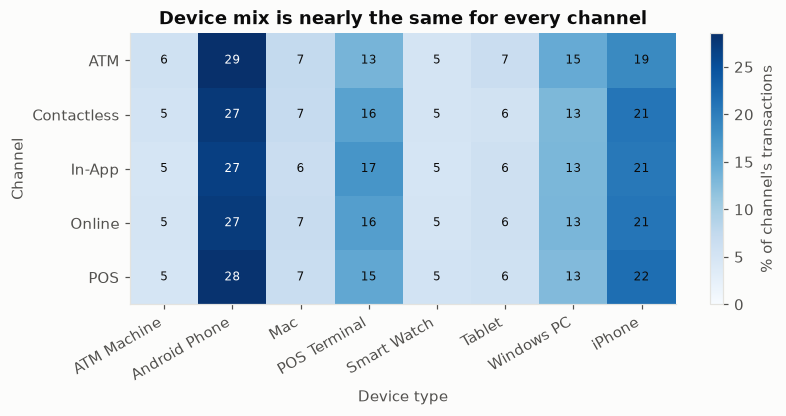

In [7]:
ct = pd.crosstab(df["channel"], df["device_type"], normalize="index") * 100
fig, ax = P.plt.subplots(figsize=(8, 3.2))
im = ax.imshow(ct.to_numpy(), cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=30, ha="right")
ax.set_yticks(range(ct.shape[0]), ct.index)
ax.set_xlabel("Device type")
ax.set_ylabel("Channel")
ax.grid(False)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(
            j,
            i,
            f"{ct.iat[i, j]:.0f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if ct.iat[i, j] > 25 else P.INK,
        )
fig.colorbar(im, ax=ax, label="% of channel's transactions")
ax.set_title("Device mix is nearly the same for every channel")
P.save(fig, "p1_channel_vs_device")
P.plt.show()

In [8]:
# How similar is the device mix across channels? Max absolute difference (percentage points)
# between any channel's device share and the overall device share.
overall_dev = df["device_type"].value_counts(normalize=True) * 100
max_pp_gap = float((ct - overall_dev[ct.columns]).abs().to_numpy().max())
_, p_chan_dev, _, _ = chi2_contingency(pd.crosstab(df["channel"], df["device_type"]))
display(
    Markdown(
        f"Largest gap between a channel's device share and the overall device share: "
        f"**{max_pp_gap:.1f} percentage points**; chi-square test of channel × device independence "
        f"p = **{p_chan_dev:.2g}**."
    )
)

Largest gap between a channel's device share and the overall device share: **2.3 percentage points**; chi-square test of channel × device independence p = **0.44**.

**Reading.** Channel and device type look close to statistically independent: an ATM
transaction is about as likely to come from a phone as an online one is. Real card data would show
strong structure here (ATM transactions on ATM machines). This pattern is *consistent with* the
columns having been sampled independently, which is typical of synthetic data. We do not conclude
that the data is synthetic, but it reinforces the rule of not claiming real-world performance.

## 5. Class balance and locked splits

The split was created **before** any label-based analysis by `scripts/make_splits.py` and saved to
`data/splits/splits.csv` (see `notes/00_preregistration.md`):

- **holdout** (20%, stratified) — scored once at the end of modelling;
- **dev** (80%) — 5-fold stratified CV, repeated 3 times with different shuffles.

In [9]:
dfs = attach_splits(df)
rows = []
for name, part in [("all", dfs), *dfs.groupby("split")]:
    k, n = int(part[C.TARGET].sum()), len(part)
    lo, hi = S.wilson_ci(k, n)
    rows.append(
        {
            "subset": name,
            "n": n,
            "n_fraud": k,
            "fraud_rate_%": 100 * k / n,
            "ci95_low_%": 100 * float(lo),
            "ci95_high_%": 100 * float(hi),
        }
    )
balance = pd.DataFrame(rows)
balance.round(3)

,subset,n,n_fraud,fraud_rate_%,ci95_low_%,ci95_high_%
0,all,20000,339,1.695,1.525,1.883
1,dev,16000,271,1.694,1.505,1.906
2,holdout,4000,68,1.700,1.343,2.149


In [10]:
fold_rows = []
dev = dfs[dfs["split"] == "dev"]
for r in range(3):
    for k, part in dev.groupby(f"fold_r{r}"):
        fold_rows.append(
            {"repeat": r, "fold": k, "n": len(part), "n_fraud": int(part[C.TARGET].sum())}
        )
folds = pd.DataFrame(fold_rows)
folds.pivot(index="fold", columns="repeat", values="n_fraud").add_prefix("fraud in repeat ")

repeat,fraud in repeat 0,fraud in repeat 1,fraud in repeat 2
fold,,,
0,54,54,54
1,54,54,54
2,54,54,54
3,54,54,54
4,55,55,55


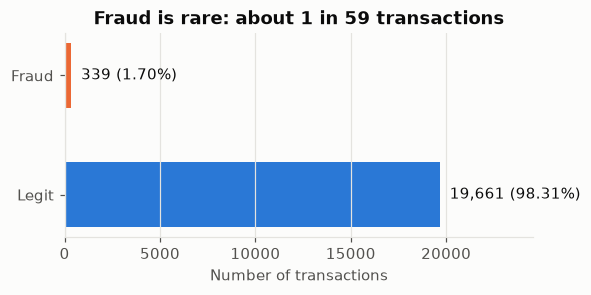

In [11]:
fig, ax = P.plt.subplots(figsize=(5.5, 2.4))
counts = df[C.TARGET].value_counts().sort_index()
ax.barh(["Legit", "Fraud"], counts.to_numpy(), color=[P.LEGIT, P.FRAUD], height=0.55)
for i, v in enumerate(counts.to_numpy()):
    ax.text(v, i, f"  {v:,} ({100 * v / counts.sum():.2f}%)", va="center", color=P.INK)
ax.set_xlabel("Number of transactions")
ax.set_xlim(0, counts.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title(f"Fraud is rare: about 1 in {round(counts.sum() / counts[1])} transactions")
P.save(fig, "p1_class_balance")
P.plt.show()

## 6. Business framing

**Who uses the model?** A card issuer's fraud team. Each incoming transaction gets a fraud score;
transactions above a threshold are flagged for review or step-up authentication.

**Questions the project answers**

1. How well can fraud be ranked from these features (PR-AUC, with uncertainty)?
2. At which threshold is the total cost of mistakes lowest, and how sensitive is that choice
   to the cost assumptions?
3. Which features drive the score, overall and for a single transaction?
4. How would we notice if incoming data drifted away from the training data?

**Pricing a mistake.** Two errors cost money in different ways:

| Outcome | What happens | Cost |
|---|---|---|
| True positive | fraud caught | review cost |
| **False positive** | good customer bothered (declined / asked to verify) | review cost + friction cost |
| **False negative** | fraud missed | share of the transaction amount lost + chargeback handling |
| True negative | nothing | 0 |

Because a missed fraud costs (part of) its amount, an expensive fraud matters more than a cheap one.
The parameters live in `configs/cost.yaml`. They are **assumptions proposed for review**; they will
not drive any decision until their status is `confirmed`.

In [12]:
cost = load_cost_params()
pd.Series(cost.to_dict(), name="value").to_frame()

,value
review_cost_per_alert,5.0
fp_friction_cost,10.0
fn_loss_fraction,1.0
fn_fixed_cost,15.0
status,accepted


## 7. Limitations recorded before modelling

- **No customer or card ID.** Customer-level features (spend history, typical merchants) cannot be
  built, and the split cannot be grouped by customer. If one customer appears in both train and
  validation, CV is optimistic by an unknown amount.
- **No real timestamp.** Only hour-of-day and day-of-week exist, so there is no out-of-time
  validation. Drift in the monitoring phase will be *simulated*.
- **Unspecified provenance.** Results describe this dataset, not real-world card fraud.
- **Small positive class.** With a few hundred fraud rows, every metric is reported with an interval.

In [13]:
summary = {
    "n_rows": len(df),
    "n_columns": df.shape[1],
    "n_features": len(C.FEATURE_COLS),
    "feature_groups": {
        "categorical": C.CATEGORICAL_COLS,
        "boolean": C.BOOLEAN_COLS,
        "discrete": C.DISCRETE_COLS,
        "continuous": C.CONTINUOUS_COLS,
    },
    "quality_checks": qc,
    "n_quality_checks": len(qc),
    "n_quality_checks_failed": n_failed,
    "plausibility_checks": plausibility_checks(df),
    "channel_device_independence": {"chi2_p_value": p_chan_dev, "max_share_gap_pp": max_pp_gap},
    "class_balance": balance.to_dict(orient="records"),
    "fold_fraud_counts": folds.to_dict(orient="records"),
    "cost_params": cost.to_dict(),
}
path = write_json(summary, "p1_data_understanding")
print(f"wrote {path.relative_to(C.ROOT)}")

wrote reports/p1_data_understanding.json


## Summary

In [14]:
b_all = balance.set_index("subset").loc["all"]
b_dev = balance.set_index("subset").loc["dev"]
b_hold = balance.set_index("subset").loc["holdout"]
worst = plaus.sort_values("n_rows", ascending=False).iloc[0]
display(
    Markdown(f"""
- **Size:** {len(df):,} transactions, {len(C.FEATURE_COLS)} features
  ({len(C.CATEGORICAL_COLS)} categorical, {len(C.BOOLEAN_COLS)} boolean,
  {len(C.NUMERIC_COLS)} numeric), plus an ID and the target.
- **Quality:** {len(qc) - n_failed} of {len(qc)} structural checks pass — no missing values,
  no duplicate rows, all categories and ranges valid.
- **Plausibility:** combinations unusual for real card traffic are common (largest:
  `{worst["rule"]}`, {int(worst["n_rows"]):,} rows = {100 * worst["share_of_rows"]:.1f}%), and channel
  and device look nearly independent (max gap {max_pp_gap:.1f} pp). Consistent with synthetic
  generation; provenance stays "unspecified".
- **Fraud rate:** {int(b_all["n_fraud"])} of {int(b_all["n"]):,} = {b_all["fraud_rate_%"]:.3f}%
  (95% CI {b_all["ci95_low_%"]:.2f}–{b_all["ci95_high_%"]:.2f}%).
- **Locked split:** dev {int(b_dev["n"]):,} rows / {int(b_dev["n_fraud"])} fraud;
  holdout {int(b_hold["n"]):,} rows / {int(b_hold["n_fraud"])} fraud; each CV validation fold holds
  {folds["n_fraud"].min()}–{folds["n_fraud"].max()} fraud.
- **Next:** notebook 02 explores which features carry signal, on the dev split only.
""")
)


- **Size:** 20,000 transactions, 24 features
  (5 categorical, 6 boolean,
  13 numeric), plus an ID and the target.
- **Quality:** 26 of 26 structural checks pass — no missing values,
  no duplicate rows, all categories and ranges valid.
- **Plausibility:** combinations unusual for real card traffic are common (largest:
  `card_present_channel_on_desktop`, 1,685 rows = 8.4%), and channel
  and device look nearly independent (max gap 2.3 pp). Consistent with synthetic
  generation; provenance stays "unspecified".
- **Fraud rate:** 339 of 20,000 = 1.695%
  (95% CI 1.53–1.88%).
- **Locked split:** dev 16,000 rows / 271 fraud;
  holdout 4,000 rows / 68 fraud; each CV validation fold holds
  54–55 fraud.
- **Next:** notebook 02 explores which features carry signal, on the dev split only.
